In [10]:
import pandas as pd
import numpy as np
import kagglehub
from kagglehub import KaggleDatasetAdapter
import os

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import pickle

c:\Users\alehe\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Cargamos el modelo de regresión logística para no estar entrenandolo desde cero cada vez

In [11]:
load_model = pickle.load(open("../modelos/LR_model.sav", 'rb'))

c:\Users\alehe\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator CountVectorizer from version 1.7.0 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\Users\alehe\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator LogisticRegression from version 1.7.0 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\Users\alehe\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle es

Caso de uso 1: Buscar productos por nombre y presentar score de estos al usuario mediante el modelo a emplear

In [ ]:
file_path = "amazon.csv"
df_amazon = kagglehub.dataset_load(KaggleDatasetAdapter.PANDAS,"karkavelrajaj/amazon-sales-dataset", file_path)

100%|██████████| 1.95M/1.95M [00:01<00:00, 1.77MB/s]

Extracting zip of amazon.csv...


In [18]:
# Categorías más comunes
df_amazon['category'].value_counts().head(10)

category
Computers&Accessories|Accessories&Peripherals|Cables&Accessories|Cables|USBCables                        233
Electronics|WearableTechnology|SmartWatches                                                               76
Electronics|Mobiles&Accessories|Smartphones&BasicMobiles|Smartphones                                      68
Electronics|HomeTheater,TV&Video|Televisions|SmartTelevisions                                             63
Electronics|Headphones,Earbuds&Accessories|Headphones|In-Ear                                              52
Electronics|HomeTheater,TV&Video|Accessories|RemoteControls                                               49
Home&Kitchen|Kitchen&HomeAppliances|SmallKitchenAppliances|MixerGrinders                                  27
Electronics|HomeTheater,TV&Video|Accessories|Cables|HDMICables                                            24
Computers&Accessories|Accessories&Peripherals|Keyboards,Mice&InputDevices|Mice                            24
Home&Kitch

In [21]:
# Buscar nombre de productos que sean laptops (incluir palabra "laptop")
laptop_products = df_amazon[df_amazon['product_name'].str.contains('laptop', case=False, na=False)]
laptop_products.head()

,product_id,product_name,category,discounted_price,actual_price,discount_percentage,rating,rating_count,about_product,user_id,user_name,review_id,review_title,review_content,img_link,product_link
1,B098NS6PVG,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...,Computers&Accessories|Accessories&Peripherals|...,₹199,₹349,43%,4.0,"43,994","Compatible with all Type C enabled devices, be...","AECPFYFQVRUWC3KGNLJIOREFP5LQ,AGYYVPDD7YG7FYNBX...","ArdKn,Nirbhay kumar,Sagar Viswanathan,Asp,Plac...","RGIQEG07R9HS2,R1SMWZQ86XIN8U,R2J3Y1WL29GWDE,RY...","A Good Braided Cable for Your Type C Device,Go...",I ordered this cable to connect my phone to An...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Ambrane-Unbreakable-Char...
9,B082LZGK39,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...,Computers&Accessories|Accessories&Peripherals|...,₹199,₹299,33%,4.0,"43,994",Universal Compatibility – It is compatible wit...,"AECPFYFQVRUWC3KGNLJIOREFP5LQ,AGYYVPDD7YG7FYNBX...","ArdKn,Nirbhay kumar,Sagar Viswanathan,Asp,Plac...","RGIQEG07R9HS2,R1SMWZQ86XIN8U,R2J3Y1WL29GWDE,RY...","A Good Braided Cable for Your Type C Device,Go...",I ordered this cable to connect my phone to An...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Ambrane-Unbreakable-Char...
17,B082LSVT4B,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...,Computers&Accessories|Accessories&Peripherals|...,₹249,₹399,38%,4.0,"43,994","Compatible with all Type C enabled devices, be...","AECPFYFQVRUWC3KGNLJIOREFP5LQ,AGYYVPDD7YG7FYNBX...","ArdKn,Nirbhay kumar,Sagar Viswanathan,Asp,Plac...","RGIQEG07R9HS2,R1SMWZQ86XIN8U,R2J3Y1WL29GWDE,RY...","A Good Braided Cable for Your Type C Device,Go...",I ordered this cable to connect my phone to An...,https://m.media-amazon.com/images/I/41d84o5-M-...,https://www.amazon.in/Ambrane-Unbreakable-Char...
21,B085194JFL,tizum HDMI to VGA Adapter Cable 1080P for Proj...,"Electronics|HomeTheater,TV&Video|Accessories|C...",₹279,₹499,44%,3.7,"10,962",Superior Stability: Built-in advanced Certifie...,"AEO5FHWNOSFBT554DKQAG4ICBGFQ,AGIQ5Y7Q4MKZ542KK...","aditya d.,Paranthaman,ashik rahman c,Rajas c.,...","R1GYK05NN6747O,R1J21BZ29NGQF9,R16JCHEILBYOMW,R...","Good product ; Average Finishing,Save it purpo...",This connector has provided as a boon for my o...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Adapter-Projector-Comput...
25,B01M4GGIVU,Tizum High Speed HDMI Cable with Ethernet | Su...,"Electronics|HomeTheater,TV&Video|Accessories|C...",₹199,₹699,72%,4.2,"12,153",Latest Standard HDMI A Male to A Male Cable: S...,"AGVUE2NFN2MQEOQ4PR525B2ZI5PQ,AFO4M4BQ2WS7A3LPK...","Yashpreet Singh,Abiram,Aakaash Ramchandani,Ami...","R2DIHMHOPYEASB,R24RHE9B30YXWQ,R3DYXQZQA6PPHM,R...",Cheap product and same is the performance but ...,The signal is too unstable once connect you ne...,https://m.media-amazon.com/images/I/41da4tk7N+...,https://www.amazon.in/TIZUM-Slim-1-5m-HDMI-Cab...


In [19]:
def map_amazon_sentiment(r):
    if r >= 4.0:
        return 'Positivo'
    elif r >= 3.0 and r < 4.0:
        return 'Neutro'
    else:
        return 'Negativo'

In [22]:
# Pasar a float todos los valores numéricos de rating
laptop_products['rating'] = pd.to_numeric(df_amazon['rating'], errors='coerce')    
laptop_products = laptop_products.dropna(subset=['rating'])
laptop_products['rating'] = laptop_products['rating'].astype(float)

<Axes: title={'center': 'Distribución de Ratings en Amazon'}, xlabel='rating'>

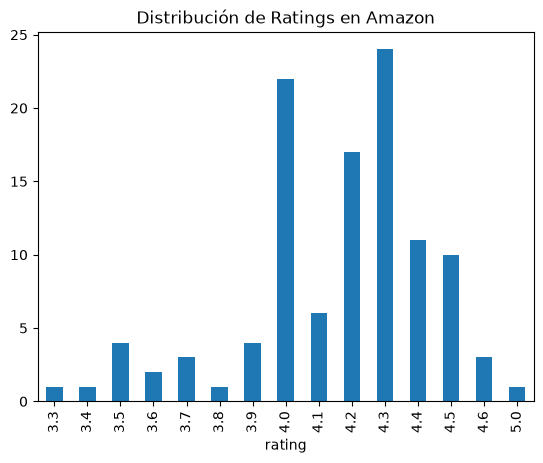

In [23]:
laptop_products["rating"].value_counts().sort_index().plot(kind='bar', title='Distribución de Ratings en Amazon')

In [24]:
laptop_products["sentiment"] = laptop_products["rating"].apply(map_amazon_sentiment)

In [26]:
with open('../modelos/LR_model.sav', 'rb') as f:
    data = pickle.load(f)

model = data['model']
vectorizer = data['vectorizer']

# Usar con reseñas de laptops
X_laptops = laptop_products['review_content']
X_vectorized = vectorizer.transform(X_laptops)
predictions = model.predict(X_vectorized)

c:\Users\alehe\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator CountVectorizer from version 1.7.0 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\Users\alehe\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator LogisticRegression from version 1.7.0 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\Users\alehe\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle es

KeyError: 'model'

In [27]:
y_test = laptop_products['sentiment']
print(classification_report(y_test, predictions))

              precision    recall  f1-score   support

      Neutro       1.00      0.88      0.93        16
    Positivo       0.98      1.00      0.99        94

    accuracy                           0.98       110
   macro avg       0.99      0.94      0.96       110
weighted avg       0.98      0.98      0.98       110



In [31]:
# Mostrar los primeros diez productos de sentiment Positivo. Mostrar solamente product_name
positive_laptops = laptop_products[laptop_products['sentiment'] == 'Positivo']
positive_laptops[['product_name']].head(10)

,product_name
1,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...
9,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...
17,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...
25,Tizum High Speed HDMI Cable with Ethernet | Su...
31,Ambrane 60W / 3A Type C Fast Charging Unbreaka...
43,TP-Link Nano AC600 USB Wi-Fi Adapter(Archer T2...
56,TP-LINK WiFi Dongle 300 Mbps Mini Wireless Net...
62,Lapster 1.5 mtr USB 2.0 Type A Male to USB A M...
63,AmazonBasics USB Type-C to USB Type-C 2.0 Cabl...
69,Amazon Basics USB Type-C to USB-A 2.0 Male Fas...


In [32]:
# Matriz de confusión
cm = confusion_matrix(y_test, predictions, labels=['Positivo', 'Neutro', 'Negativo'])
cm_df = pd.DataFrame(cm, index=['Positivo', 'Neutro', 'Negativo'], columns=['Positivo', 'Neutro', 'Negativo'])

<Axes: >

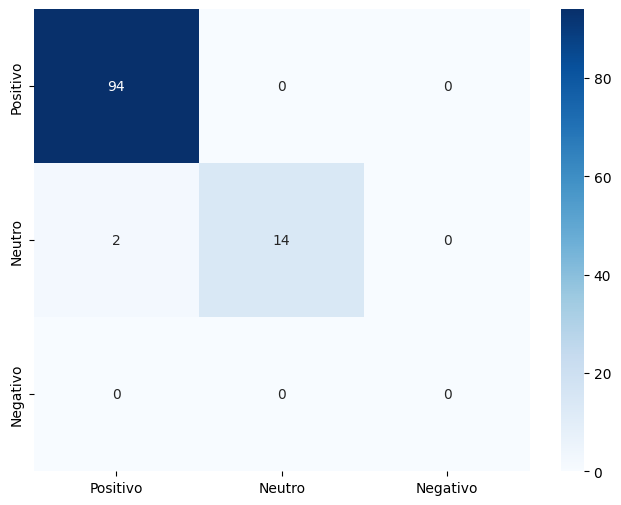

In [33]:
# Visualizar matriz de confusión
plt.figure(figsize=(8,6))
sns.heatmap(cm_df, annot=True, fmt='d', cmap='Blues')